<a href="https://colab.research.google.com/github/Paxlawa/Labu/blob/main/%D0%9B%D1%96%D0%BD%D1%96%D0%B9%D0%BD%D0%B0_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
from sklearn.linear_model import LinearRegression

X = [[1], [2], [3], [4], [5]]
y = [4.5, 7.1, 9.2, 11.8, 14.3]

model = LinearRegression()
model.fit(X, y)

X_new = [[2], [5], [8]]

predictions = model.predict(X_new)

result = pd.DataFrame({
    'x': [2, 5, 8],
    'prediction': predictions
})

print(result)

print("b1 =", model.coef_[0])
print("b1 показує, наскільки в середньому змінюється y, коли x збільшується на 1.")


   x  prediction
0  2        6.95
1  5       14.24
2  8       21.53
b1 = 2.43
b1 показує, наскільки в середньому змінюється y, коли x збільшується на 1.


In [3]:

import numpy as np
from sklearn.linear_model import LinearRegression

x2 = np.array([2, 4, 6, 8, 10])
y2 = np.array([7, 11, 16, 19, 25])

x_mean = np.mean(x2)
y_mean = np.mean(y2)

b1 = np.sum((x2 - x_mean) * (y2 - y_mean)) / np.sum((x2 - x_mean) ** 2)
b0 = y_mean - b1 * x_mean

print("Власноручно обчислені коефіцієнти:")
print("b0 =", b0)
print("b1 =", b1)

model = LinearRegression()
model.fit(x2.reshape(-1, 1), y2)

print("Коефіцієнти LinearRegression:")
print("b0 =", model.intercept_)
print("b1 =", model.coef_[0])


Власноручно обчислені коефіцієнти:
b0 = 2.3999999999999986
b1 = 2.2
Коефіцієнти LinearRegression:
b0 = 2.4000000000000004
b1 = 2.1999999999999997


In [4]:

import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([4.5, 7.1, 9.2, 11.8, 14.3])

dummy = DummyRegressor(strategy="mean")
linear = LinearRegression()

dummy.fit(X, y)
linear.fit(X, y)

y_pred_dummy = dummy.predict(X)
y_pred_linear = linear.predict(X)

def calculate_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return mae, rmse, r2

mae_dummy, rmse_dummy, r2_dummy = calculate_metrics(y, y_pred_dummy)
mae_linear, rmse_linear, r2_linear = calculate_metrics(y, y_pred_linear)

print("DummyRegressor")
print("MAE =", mae_dummy)
print("RMSE =", rmse_dummy)
print("R² =", r2_dummy)

print("\nLinearRegression")
print("MAE =", mae_linear)
print("RMSE =", rmse_linear)
print("R² =", r2_linear)


DummyRegressor
MAE = 2.9360000000000004
RMSE = 3.4382553715511013
R² = 0.0

LinearRegression
MAE = 0.08399999999999981
RMSE = 0.10862780491200254
R² = 0.9990018271638357


In [5]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = X.ravel() ** 2 + np.random.normal(0, 2, 100)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

results = []

for degree in [2, 6, 10]:
    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    results.append({
        "degree": degree,
        "train_rmse": train_rmse,
        "test_rmse": test_rmse
    })

table = pd.DataFrame(results)
print(table)

best_degree = table.loc[table["test_rmse"].idxmin(), "degree"]
print("Найкращий ступінь:", best_degree)


   degree  train_rmse  test_rmse
0       2    2.115977   2.009267
1       6    2.093341   2.152346
2      10    1.995242   2.646343
Найкращий ступінь: 2


In [6]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = X.ravel() ** 2 + np.random.normal(0, 2, 100)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1))
    ]),
    "ElasticNet": Pipeline([
        ("scaler", StandardScaler()),
        ("model", ElasticNet(alpha=0.1, l1_ratio=0.5))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

table = pd.DataFrame(results)
print(table.round(4))


              model     MAE    RMSE      R2
0  LinearRegression  2.4977  3.2603 -0.1374
1             Ridge  2.4957  3.2579 -0.1357
2             Lasso  2.4549  3.2089 -0.1018
3        ElasticNet  2.4697  3.2264 -0.1139


In [7]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = X.ravel() ** 2 + np.random.normal(0, 2, 100)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1))
    ]),
    "ElasticNet": Pipeline([
        ("scaler", StandardScaler()),
        ("model", ElasticNet(alpha=0.1, l1_ratio=0.5))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

table = pd.DataFrame(results)
print(table.round(4))


              model     MAE    RMSE      R2
0  LinearRegression  2.7867  3.3136 -0.0519
1             Ridge  2.7867  3.3137 -0.0520
2             Lasso  2.7934  3.3207 -0.0564
3        ElasticNet  2.7927  3.3203 -0.0561


In [9]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

housing = pd.DataFrame({
    "area": [50, 65, 70, 80, 90, 100, 110, 120, 130, 140],
    "rooms": [2, 3, 3, 3, 4, 4, 4, 5, 5, 6],
    "price": [150, 190, 210, 230, 270, 300, 320, 360, 390, 420]
})

housing["condition"] = [
    "good", "new", "good", "needs_repair", "good",
    "new", "good", "new", "needs_repair", "good"
]

X = housing.drop(columns=["price"])
y = housing["price"]

numerical_features = ["area", "rooms"]
categorical_features = ["condition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Test RMSE:", rmse)


Test RMSE: 12.038503524431578


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diabetes = load_diabetes(as_frame=True)

X = diabetes.data
y = diabetes.target

print(X.head())
print(X.shape)
print(X.info())
print(y.describe())


        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
(442, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1 

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Навчальні дані:", X_train.shape)
print("Тестові дані:", X_test.shape)


Навчальні дані: (353, 10)
Тестові дані: (89, 10)


In [12]:

models = {
    "DummyRegressor": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression()
}

baseline_results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    baseline_results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

baseline_table = pd.DataFrame(baseline_results)
print(baseline_table.round(4))


              model      MAE     RMSE      R2
0    DummyRegressor  64.0065  73.2225 -0.0120
1  LinearRegression  42.7941  53.8534  0.4526


In [13]:

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=20000))
])

elastic_net = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(max_iter=20000))
])


In [14]:

ridge_search = GridSearchCV(
    ridge,
    {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_root_mean_squared_error"
)

lasso_search = GridSearchCV(
    lasso,
    {"model__alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    scoring="neg_root_mean_squared_error"
)

elastic_search = GridSearchCV(
    elastic_net,
    {
        "model__alpha": [0.001, 0.01, 0.1, 1, 10],
        "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
    },
    cv=5,
    scoring="neg_root_mean_squared_error"
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)
elastic_search.fit(X_train, y_train)

print("Ridge:", ridge_search.best_params_)
print("Lasso:", lasso_search.best_params_)
print("ElasticNet:", elastic_search.best_params_)


Ridge: {'model__alpha': 10}
Lasso: {'model__alpha': 1}
ElasticNet: {'model__alpha': 0.1, 'model__l1_ratio': 0.1}


In [15]:

best_models = {
    "DummyRegressor": models["DummyRegressor"],
    "LinearRegression": models["LinearRegression"],
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "ElasticNet": elastic_search.best_estimator_
}

results = []

for name, model in best_models.items():
    predictions = model.predict(X_test)

    results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_table = pd.DataFrame(results).sort_values("RMSE")
print(results_table.round(4))


              model      MAE     RMSE      R2
3             Lasso  42.8030  53.1467  0.4669
4        ElasticNet  42.9495  53.4878  0.4600
2             Ridge  42.8568  53.6263  0.4572
1  LinearRegression  42.7941  53.8534  0.4526
0    DummyRegressor  64.0065  73.2225 -0.0120


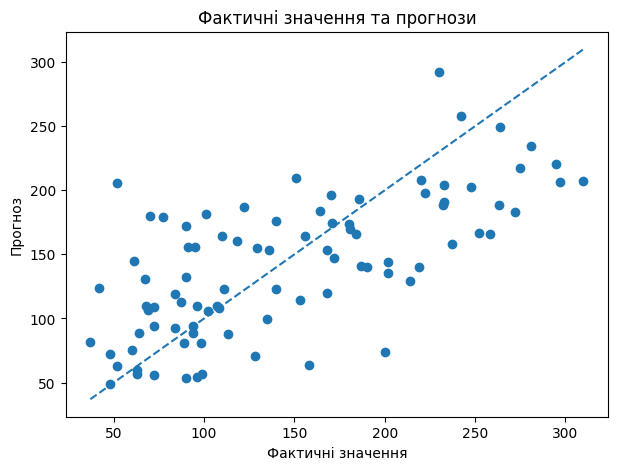

In [19]:

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt

diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

best_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.xlabel("Фактичні значення")
plt.ylabel("Прогноз")
plt.title("Фактичні значення та прогнози")
plt.show()


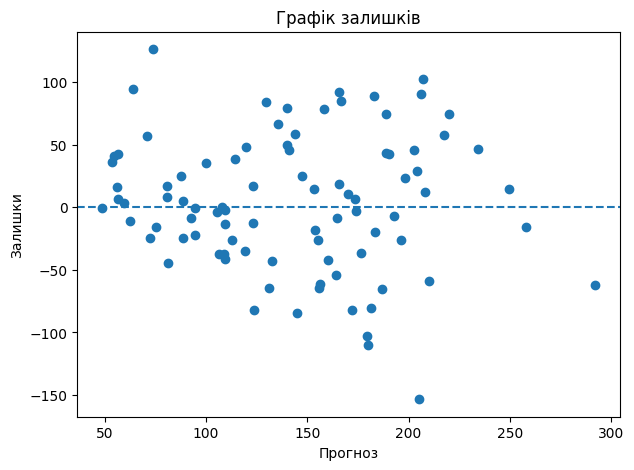

In [20]:

residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Прогноз")
plt.ylabel("Залишки")
plt.title("Графік залишків")
plt.show()


In [22]:

import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

best_model_name = "Ridge"

best_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

best_model.fit(X_train, y_train)

regressor = best_model.named_steps["model"]

coefficients = pd.DataFrame({
    "feature": X.columns,
    "coefficient": regressor.coef_
})

coefficients["abs_coefficient"] = coefficients["coefficient"].abs()
coefficients = coefficients.sort_values(
    "abs_coefficient", ascending=False
)

print("Найкраща модель:", best_model_name)
print("Вільний член:", regressor.intercept_)
print(coefficients.drop(columns="abs_coefficient").round(4))


Найкраща модель: Ridge
Вільний член: 153.73654390934846
  feature  coefficient
4      s1     -34.6720
8      s5      31.3784
2     bmi      25.7327
5      s2      17.0531
3      bp      16.7343
7      s4      11.7643
1     sex     -11.4482
6      s3       3.3699
9      s6       2.4581
0     age       1.8073
